# Conditional Flow Matching：解析 OT、OT-CFM 与 SB-CFM

本 notebook 使用二维与一维高斯分布，为论文中的每个核心结论分别提供解析参考、数值指标和可视化实验。全部代码均包含在当前文件中，不依赖额外 Python 模块。

> 运行环境：`conda activate pytorch`。默认训练 I-CFM、Minibatch OT-CFM、Analytical OT-CFM 和 SB-CFM；如需缩短试运行时间，可在第一个代码单元降低 `TRAIN_STEPS` 与 `SB_TRAIN_STEPS`。


下面给出一套**可以直接复制到同一个 Jupyter Notebook 中运行的完整实验**。

不使用图像数据集，也不需要创建额外的 Python 文件。所有数据都由高斯分布生成，模型统一使用 PyTorch MLP。

实验重点不是简单比较生成效果，而是逐项验证论文中的数学结论。

## 一、实验设计

我们选择两个层次的实验。

**第一层：二维高斯分布。**

使用：

$$
q_0=\mathcal N(\mu_0,\Sigma_0)
$$

$$
q_1=\mathcal N(\mu_1,\Sigma_1)
$$

由于高斯分布之间的二次 Wasserstein 距离、最优传输映射和位移插值都具有解析解，因此可以直接验证 OT-CFM 是否逼近理论上的 Dynamic OT。

**第二层：一维高斯分布。**

使用一维高斯构造 Schrödinger Bridge。由于熵正则化 OT 耦合也具有解析解，可以精确验证 SB-CFM 的边缘概率路径。

我们设计六个实验：

| 实验 | 验证目标 | 是否训练 |
|---|---|---|
| 1 | Static OT 确实降低端点运输成本 | 否 |
| 2 | Static OT + Linear Interpolation = Dynamic OT | 否 |
| 3 | OT-CFM 比 I-CFM 更接近 Dynamic OT | 是 |
| 4 | OT-CFM 降低条件速度监督方差 | 否，复用模型 |
| 5 | OT-CFM 改善低 NFE 下的 ODE 采样 | 否，复用模型 |
| 6 | SB-CFM 恢复 Schrödinger Bridge 边缘分布 | 是 |

为了避免 Minibatch OT 近似误差干扰理论验证，实验 1、2 同时使用**解析 OT**作为 Ground Truth。实验 3 再加入 Minibatch OT，验证实际算法的表现。

---

# 二、实验 0：环境与数据分布

### 实验目标

建立统一的二维高斯分布，并实现解析 OT。

对于两个高斯分布：

$$
q_0=\mathcal N(\mu_0,\Sigma_0)
$$

$$
q_1=\mathcal N(\mu_1,\Sigma_1)
$$

二次 Wasserstein 距离为：

$$
\boxed{
W_2^2(q_0,q_1)
=
\|\mu_0-\mu_1\|^2+
\operatorname{Tr}
\left(
\Sigma_0+\Sigma_1
-
2(\Sigma_0^{1/2}\Sigma_1\Sigma_0^{1/2})^{1/2}
\right)
}
\tag{1}
$$

对应最优 Monge Map：

$$
\boxed{
T(x)=\mu_1+A(x-\mu_0)
}
\tag{2}
$$

其中：

$$
\boxed{
A=
\Sigma_0^{-1/2}
(\Sigma_0^{1/2}\Sigma_1\Sigma_0^{1/2})^{1/2}
\Sigma_0^{-1/2}
}
\tag{3}
$$

后面用它作为理论参考。

### 导入依赖


In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

from scipy.optimize import linear_sum_assignment

SEED = 42
TRAIN_STEPS = 5000
SB_TRAIN_STEPS = 5000

torch.manual_seed(SEED)
np.random.seed(SEED)
if not torch.cuda.is_available():
    torch.set_num_threads(min(8, torch.get_num_threads()))

device = "cuda" if torch.cuda.is_available() else "cpu"
dtype = torch.float32

print("Device:", device)


Device: cuda


### 构造二维高斯分布


In [2]:
# 两个二维高斯分布
mu0 = torch.tensor([-2.0, 0.0], device=device)
mu1 = torch.tensor([2.0, 1.0], device=device)

Sigma0 = torch.tensor([
    [1.0, 0.0],
    [0.0, 0.25]
], device=device)

Sigma1 = torch.tensor([
    [0.25, 0.0],
    [0.0, 1.0]
], device=device)

def sqrtm_spd(A):
    # 对称正定矩阵的平方根
    eigvals, eigvecs = torch.linalg.eigh(A)
    return (eigvecs * eigvals.clamp_min(1e-12).sqrt()) @ eigvecs.T

def invsqrtm_spd(A):
    eigvals, eigvecs = torch.linalg.eigh(A)
    return (eigvecs * eigvals.clamp_min(1e-12).rsqrt()) @ eigvecs.T

S0_sqrt = sqrtm_spd(Sigma0)
S0_invsqrt = invsqrtm_spd(Sigma0)

# 解析 OT Map
A = (
    S0_invsqrt
    @ sqrtm_spd(S0_sqrt @ Sigma1 @ S0_sqrt)
    @ S0_invsqrt
)

def sample_q0(n):
    z = torch.randn(n, 2, device=device)
    return mu0 + z @ S0_sqrt.T

def sample_q1(n):
    z = torch.randn(n, 2, device=device)
    return mu1 + z @ sqrtm_spd(Sigma1).T

def ot_map(x):
    return mu1 + (x - mu0) @ A.T

# 解析 Wasserstein 距离平方
W2_sq = (
    torch.sum((mu0 - mu1) ** 2)
    + torch.trace(
        Sigma0 + Sigma1
        - 2 * sqrtm_spd(S0_sqrt @ Sigma1 @ S0_sqrt)
    )
).item()

print("OT Map A:\n", A)
print("Analytical W2^2:", W2_sq)


OT Map A:
 

tensor([[0.5000, 0.0000],
        [0.0000, 2.0000]], device='cuda:0')
Analytical W2^2: 17.5


在这个例子中，两个协方差矩阵都是对角矩阵，因此：

$$
A=
\begin{bmatrix}
0.5&0\\
0&2
\end{bmatrix}
$$

解析 Wasserstein 距离平方为：

$$
\boxed{W_2^2=17.5}
$$

后续所有 Path Energy 都应该与这个数值比较。

---

# 三、实验 1：验证 Static OT 降低运输成本

## 3.1 验证目标

比较三种端点 Coupling：

1. Independent Coupling。
2. Minibatch OT Coupling。
3. Analytical OT Coupling。

理论上：

$$
\boxed{
C_{\mathrm{Analytical\ OT}}
\le
C_{\mathrm{Minibatch\ OT}}
\le
C_{\mathrm{Independent}}
}
\tag{4}
$$

这里的不等式指总体期望运输成本；有限次 Monte Carlo 估计可能存在波动。

其中解析 OT 成本等于：

$$
W_2^2(q_0,q_1)
$$

## 3.2 实验代码

### 计算三种 Coupling


In [3]:
@torch.no_grad()
def minibatch_ot_pair(x0, x1):
    # 匈牙利算法求解等权离散 OT
    cost = torch.cdist(x0, x1).square()
    row, col = linear_sum_assignment(cost.cpu().numpy())

    row = torch.as_tensor(row, device=x0.device)
    col = torch.as_tensor(col, device=x1.device)

    return x0[row], x1[col]

@torch.no_grad()
def coupling_experiment(n=1000, batch_size=128):
    independent_cost = []
    minibatch_cost = []
    analytical_cost = []

    for _ in range(n):
        x0 = sample_q0(batch_size)
        x1 = sample_q1(batch_size)

        # Independent Coupling
        independent_cost.append(
            ((x1 - x0) ** 2).sum(-1).mean().item()
        )

        # Minibatch OT
        a, b = minibatch_ot_pair(x0, x1)
        minibatch_cost.append(
            ((b - a) ** 2).sum(-1).mean().item()
        )

        # Analytical OT
        x1_ot = ot_map(x0)
        analytical_cost.append(
            ((x1_ot - x0) ** 2).sum(-1).mean().item()
        )

    return {
        "Independent": np.mean(independent_cost),
        "Minibatch OT": np.mean(minibatch_cost),
        "Analytical OT": np.mean(analytical_cost),
    }

costs = coupling_experiment()

print(pd.DataFrame({
    "Method": list(costs.keys()),
    "Transport Cost": list(costs.values())
}))

print("Theoretical W2^2:", W2_sq)


          Method  Transport Cost
0    Independent       19.472132
1   Minibatch OT       17.565368
2  Analytical OT       17.484433
Theoretical W2^2: 17.5


## 3.3 可视化端点配对



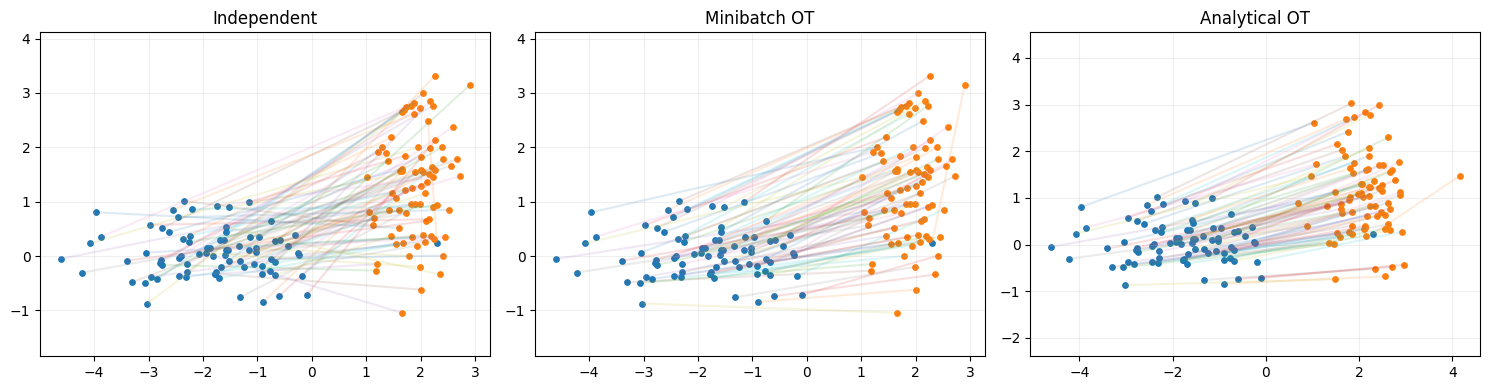

In [4]:
x0 = sample_q0(80)
x1 = sample_q1(80)

# Independent
pairs_ind = (x0, x1)

# Minibatch OT
pairs_mb = minibatch_ot_pair(x0, x1)

# Analytical OT
pairs_ot = (x0, ot_map(x0))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (a, b), title in zip(
    axes,
    [pairs_ind, pairs_mb, pairs_ot],
    ["Independent", "Minibatch OT", "Analytical OT"]
):
    a = a.cpu().numpy()
    b = b.cpu().numpy()

    ax.scatter(a[:, 0], a[:, 1], s=15, label="Source")
    ax.scatter(b[:, 0], b[:, 1], s=15, label="Target")

    for i in range(len(a)):
        ax.plot(
            [a[i, 0], b[i, 0]],
            [a[i, 1], b[i, 1]],
            alpha=0.15
        )

    ax.set_title(title)
    ax.axis("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 预期结果

Independent Coupling 存在大量交叉配对。

Minibatch OT 会显著减少不必要的运输距离。

Analytical OT 则具有最优的总体运输成本。

**这个实验验证：Static OT 的作用就是优化端点之间的配对关系。**

---

# 四、实验 2：验证 Static OT + Linear Interpolation = Dynamic OT

这是对 Benamou–Brenier 定理的直接数值验证。

## 4.1 理论

给定解析 OT：

$$
X_1=T(X_0)
$$

采用线性插值：

$$
\boxed{
X_t=(1-t)X_0+tT(X_0)
}
\tag{5}
$$

速度为：

$$
\boxed{
\dot X_t=T(X_0)-X_0
}
\tag{6}
$$

因此：

$$
\begin{aligned}
\mathcal A
&=
\mathbb E\int_0^1\|\dot X_t\|^2dt\\
&=
\mathbb E\|T(X_0)-X_0\|^2\\
&=
W_2^2(q_0,q_1)
\end{aligned}
$$

即：

$$
\boxed{
\mathcal A=W_2^2(q_0,q_1)
}
\tag{7}
$$

同时，高斯位移插值的中间分布也有解析解：

$$
\boxed{
p_t=\mathcal N(\mu_t,\Sigma_t)
}
\tag{8}
$$

其中：

$$
\mu_t=(1-t)\mu_0+t\mu_1
$$

$$
\boxed{
\Sigma_t=
[(1-t)I+tA]
\Sigma_0
[(1-t)I+tA]^T
}
\tag{9}
$$

因此，我们可以同时验证：

- 轨迹是否为直线。
- 动能是否等于 $W_2^2$。
- 中间分布是否符合解析位移插值。

## 4.2 实验代码

### 解析 Dynamic OT


In [5]:
@torch.no_grad()
def analytical_dynamic_ot(n=10000):
    x0 = sample_q0(n)
    x1 = ot_map(x0)

    ts = torch.linspace(0, 1, 21, device=device)

    energies = []
    mean_errors = []
    cov_errors = []

    I = torch.eye(2, device=device)

    for t in ts:
        xt = (1 - t) * x0 + t * x1

        # 每条轨迹的速度恒定
        velocity = x1 - x0
        energies.append(
            velocity.square().sum(-1).mean().item()
        )

        # 理论中间高斯
        mu_t = (1 - t) * mu0 + t * mu1
        B_t = (1 - t) * I + t * A
        Sigma_t = B_t @ Sigma0 @ B_t.T

        # 经验均值和协方差
        empirical_mu = xt.mean(0)
        centered = xt - empirical_mu
        empirical_cov = centered.T @ centered / (n - 1)

        mean_errors.append(
            torch.norm(empirical_mu - mu_t).item()
        )
        cov_errors.append(
            torch.norm(empirical_cov - Sigma_t).item()
        )

    # 时间积分
    path_energy = np.trapz(energies, ts.cpu().numpy())

    return ts.cpu().numpy(), energies, path_energy, mean_errors, cov_errors

ts, energies, path_energy, mean_errors, cov_errors = analytical_dynamic_ot()

print("Theoretical W2^2:", W2_sq)
print("Estimated Path Energy:", path_energy)
print("Absolute Error:", abs(path_energy - W2_sq))


Theoretical W2^2: 17.5
Estimated Path Energy: 17.57547378540039
Absolute Error: 0.07547378540039062


### 绘制动能曲线


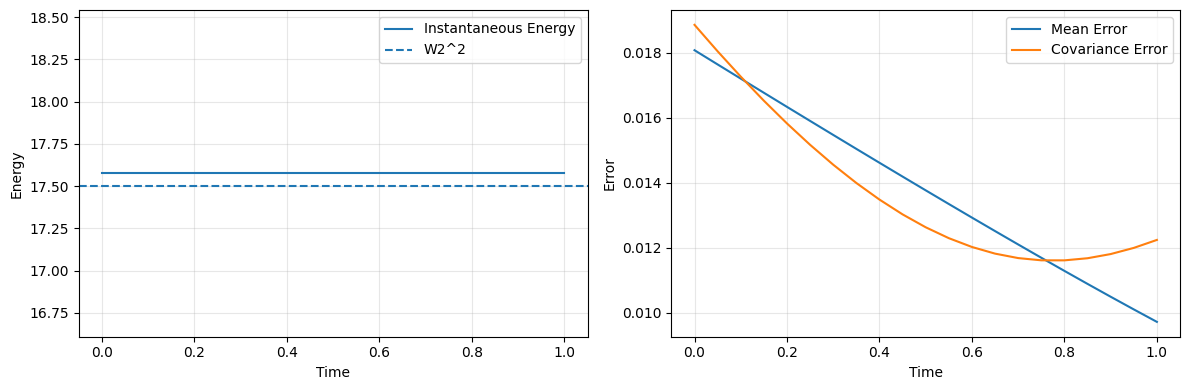

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(ts, energies, label="Instantaneous Energy")
axes[0].axhline(W2_sq, linestyle="--", label="W2^2")
axes[0].set_xlabel("Time")
axes[0].set_ylabel("Energy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(ts, mean_errors, label="Mean Error")
axes[1].plot(ts, cov_errors, label="Covariance Error")
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Error")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 预期结果

首先：

$$
\boxed{
\widehat{\mathcal A}\approx17.5
}
$$

其次，中间高斯分布的均值和协方差误差应当很小。

这个实验说明：

**Static OT 先解决端点配对，再进行匀速直线插值，就能够构造 Dynamic OT 的最优概率路径。**

这里的最优性不需要神经网络训练，是数学构造本身具有的性质。

---

# 五、实验 3：训练 I-CFM 与 OT-CFM

前两个实验验证的是理论构造。

现在开始验证：

**神经网络能否通过 CFM 学到这些概率路径？**

我们训练三个模型：

1. I-CFM：独立耦合。
2. Minibatch OT-CFM：Batch 内 OT 耦合。
3. Analytical OT-CFM：解析 OT 耦合。

第三个模型是理想参考，用于区分 Minibatch OT 误差和神经网络拟合误差。

## 5.1 模型

输入：

$$
(t,x_t)\in\mathbb R^3
$$

输出：

$$
v_\theta(t,x_t)\in\mathbb R^2
$$

统一使用 MLP。

### 模型定义


In [7]:
class VelocityMLP(nn.Module):
    def __init__(self, dim=2, hidden=128):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(dim + 1, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, hidden),
            nn.SiLU(),
            nn.Linear(hidden, dim)
        )

    def forward(self, x, t):
        if not torch.is_tensor(t):
            t = torch.tensor(t, device=x.device, dtype=x.dtype)

        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]

        inp = torch.cat([x, t], dim=-1)
        return self.net(inp)


## 5.2 CFM 训练目标

统一使用：

$$
\boxed{
X_t=(1-t)X_0+tX_1+\sigma Z
}
\tag{10}
$$

$$
\boxed{
U=X_1-X_0
}
\tag{11}
$$

损失：

$$
\boxed{
\mathcal L=
\mathbb E\|v_\theta(t,X_t)-U\|^2
}
\tag{12}
$$

三种方法只改变端点 Coupling。

为了尽量逼近无平滑的 Dynamic OT，我们选择：

$$
\sigma=0.05
$$

需要注意：固定噪声 $\sigma>0$ 时，I-CFM 与 OT-CFM 的严格端点分布是经过高斯平滑的 $q_0,q_1$。后面评估时从未平滑的 $q_0$ 出发，是一种小噪声近似。解析 Dynamic OT 的严格等价性仍然对应 $\sigma=0$。

## 5.3 训练代码

### 采样不同 Coupling


In [8]:
@torch.no_grad()
def sample_coupling(batch_size, method):
    x0 = sample_q0(batch_size)

    if method == "independent":
        x1 = sample_q1(batch_size)

    elif method == "minibatch_ot":
        x1 = sample_q1(batch_size)
        x0, x1 = minibatch_ot_pair(x0, x1)

    elif method == "analytical_ot":
        x1 = ot_map(x0)

    else:
        raise ValueError(method)

    return x0, x1


### 统一训练函数


In [9]:
def train_cfm(
    method,
    steps=5000,
    batch_size=256,
    lr=1e-3,
    sigma=0.05
):
    torch.manual_seed(42)

    model = VelocityMLP().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    losses = []

    for step in range(steps):
        x0, x1 = sample_coupling(batch_size, method)

        t = torch.rand(batch_size, 1, device=device)
        z = torch.randn_like(x0)

        # 条件概率路径
        xt = (1 - t) * x0 + t * x1 + sigma * z

        # 条件速度监督
        target = x1 - x0

        pred = model(xt, t)

        loss = F.mse_loss(pred, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if (step + 1) % 1000 == 0:
            print(
                f"{method:15s} "
                f"step={step+1:5d} "
                f"loss={loss.item():.6f}"
            )

    return model, losses


### 训练三个模型


In [10]:
models = {}
loss_history = {}

methods = [
    "independent",
    "minibatch_ot",
    "analytical_ot"
]

for method in methods:
    print("\nTraining:", method)

    model, losses = train_cfm(
        method=method,
        steps=TRAIN_STEPS,
        batch_size=256,
        sigma=0.05
    )

    models[method] = model
    loss_history[method] = losses



Training: independent


independent     step= 1000 loss=0.810656


independent     step= 2000 loss=0.802279


independent     step= 3000 loss=0.800871


independent     step= 4000 loss=0.847430


...

analytical_ot   step= 1000 loss=0.003090


analytical_ot   step= 2000 loss=0.001441


analytical_ot   step= 3000 loss=0.001383


analytical_ot   step= 4000 loss=0.001615


analytical_ot   step= 5000 loss=0.001251


### 绘制训练损失


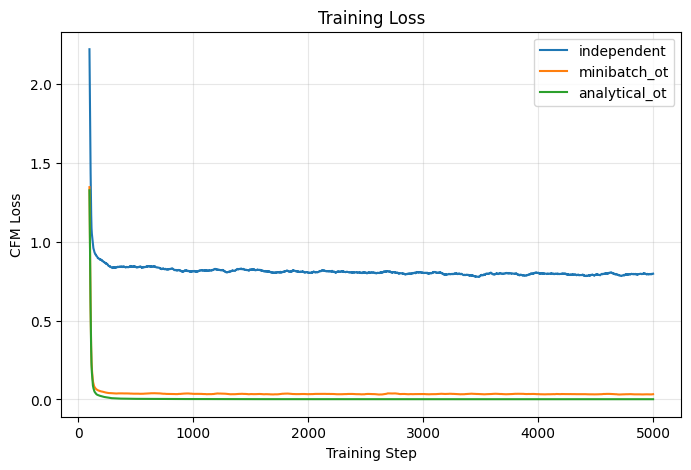

In [11]:
plt.figure(figsize=(8, 5))

for method, losses in loss_history.items():
    # 平滑显示
    smooth = pd.Series(losses).rolling(100).mean()
    plt.plot(smooth, label=method)

plt.xlabel("Training Step")
plt.ylabel("CFM Loss")
plt.title("Training Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 如何解释结果？

OT-CFM 的训练 Loss 可能低于 I-CFM。

但这里不能简单认为：

$$
\text{Loss 更低}
\Longrightarrow
\text{生成模型更好}
$$

因为三种方法的监督目标分布不同。

尤其是 I-CFM：

$$
U=X_1-X_0
$$

具有更大的总体方差。

因此，后面需要单独计算条件速度方差、实际 Path Energy 和生成误差。

---

# 六、实验 4：比较实际 ODE Path Energy

## 6.1 验证目标

前面解析 Dynamic OT 的 Path Energy 为：

$$
W_2^2=17.5
$$

现在对三个训练好的模型分别进行 ODE 积分，计算实际动能：

$$
\boxed{
\mathcal A_\theta
=
\mathbb E\int_0^1
\|v_\theta(t,X_t)\|^2dt
}
\tag{13}
$$

并定义：

$$
\boxed{
\mathrm{NPE}
=
\frac{|\mathcal A_\theta-W_2^2|}
{W_2^2}
}
\tag{14}
$$

同时计算生成终点分布的均值、协方差与目标分布之间的误差。

由于目标分布是高斯，可以先使用高斯矩匹配 Wasserstein 距离：

$$
W_2^2
\left(
\mathcal N(\widehat\mu,\widehat\Sigma),
\mathcal N(\mu_1,\Sigma_1)
\right)
$$

需要注意，生成分布未必严格是高斯，因此该指标只能检验一、二阶矩，不是一般分布的真实 Wasserstein 距离。我们另外加入样本级离散 OT 指标。

## 6.2 ODE 求解器

### Euler / Heun / RK4


In [12]:
@torch.no_grad()
def ode_sample(model, x0, steps=100, solver="rk4", return_path=False):
    x = x0.clone()
    dt = 1.0 / steps

    path = [x.clone()]
    energy = 0.0

    for k in range(steps):
        t = k * dt

        if solver == "euler":
            k1 = model(x, t)
            x_new = x + dt * k1

            # 左端点积分
            energy += dt * k1.square().sum(-1).mean().item()

        elif solver == "heun":
            k1 = model(x, t)
            x_pred = x + dt * k1
            k2 = model(x_pred, t + dt)

            x_new = x + 0.5 * dt * (k1 + k2)

            energy += (
                0.5 * dt *
                (
                    k1.square().sum(-1).mean().item()
                    + k2.square().sum(-1).mean().item()
                )
            )

        elif solver == "rk4":
            k1 = model(x, t)
            k2 = model(x + 0.5 * dt * k1, t + 0.5 * dt)
            k3 = model(x + 0.5 * dt * k2, t + 0.5 * dt)
            k4 = model(x + dt * k3, t + dt)

            x_new = x + dt / 6 * (
                k1 + 2*k2 + 2*k3 + k4
            )

            # Simpson 型动能积分
            e1 = k1.square().sum(-1).mean().item()
            e2 = k2.square().sum(-1).mean().item()
            e3 = k3.square().sum(-1).mean().item()
            e4 = k4.square().sum(-1).mean().item()

            energy += dt / 6 * (e1 + 2*e2 + 2*e3 + e4)

        else:
            raise ValueError(solver)

        x = x_new

        if return_path:
            path.append(x.clone())

    if return_path:
        return x, energy, torch.stack(path)

    return x, energy


## 6.3 评价指标

### 高斯矩匹配 W2


In [13]:
@torch.no_grad()
def gaussian_w2_sq(mu_a, cov_a, mu_b, cov_b):
    sqrt_a = sqrtm_spd(cov_a)

    middle = sqrt_a @ cov_b @ sqrt_a
    sqrt_middle = sqrtm_spd(middle)

    value = (
        (mu_a - mu_b).square().sum()
        + torch.trace(cov_a + cov_b - 2 * sqrt_middle)
    )

    return value.clamp_min(0).item()

@torch.no_grad()
def empirical_gaussian_w2(x, target_mu, target_cov):
    mu = x.mean(0)
    centered = x - mu
    cov = centered.T @ centered / (len(x) - 1)

    return np.sqrt(
        gaussian_w2_sq(mu, cov, target_mu, target_cov)
    )


### 离散样本 OT 评价


In [14]:
@torch.no_grad()
def empirical_ot_w2(x, y, max_samples=512):
    # 等权离散 OT，使用匈牙利算法
    n = min(len(x), len(y), max_samples)

    x = x[:n]
    y = y[:n]

    C = torch.cdist(x, y).square().cpu().numpy()
    row, col = linear_sum_assignment(C)

    return float(np.sqrt(C[row, col].mean()))


注意：这里得到的是两个经验分布之间的离散 $W_2$ 估计，存在有限样本偏差。比较不同模型时，应该使用相同的目标样本集合。

### 实际 Path Energy 与生成误差


In [15]:
x0_eval = sample_q0(4096)
target_eval = sample_q1(4096)

results = []

for method, model in models.items():
    model.eval()

    x1_pred, energy = ode_sample(
        model,
        x0_eval,
        steps=200,
        solver="rk4"
    )

    npe = abs(energy - W2_sq) / W2_sq

    moment_w2 = empirical_gaussian_w2(
        x1_pred, mu1, Sigma1
    )

    sample_w2 = empirical_ot_w2(
        x1_pred, target_eval
    )

    results.append({
        "Method": method,
        "Path Energy": energy,
        "NPE": npe,
        "Moment W2": moment_w2,
        "Sample W2": sample_w2
    })

df_results = pd.DataFrame(results)
print(df_results)


          Method  Path Energy       NPE  Moment W2  Sample W2
0    independent    18.010872  0.029193   0.047424   0.226879
1   minibatch_ot    17.798956  0.017083   0.061830   0.208156
2  analytical_ot    17.333356  0.009523   0.018273   0.210383


## 6.4 可视化生成轨迹



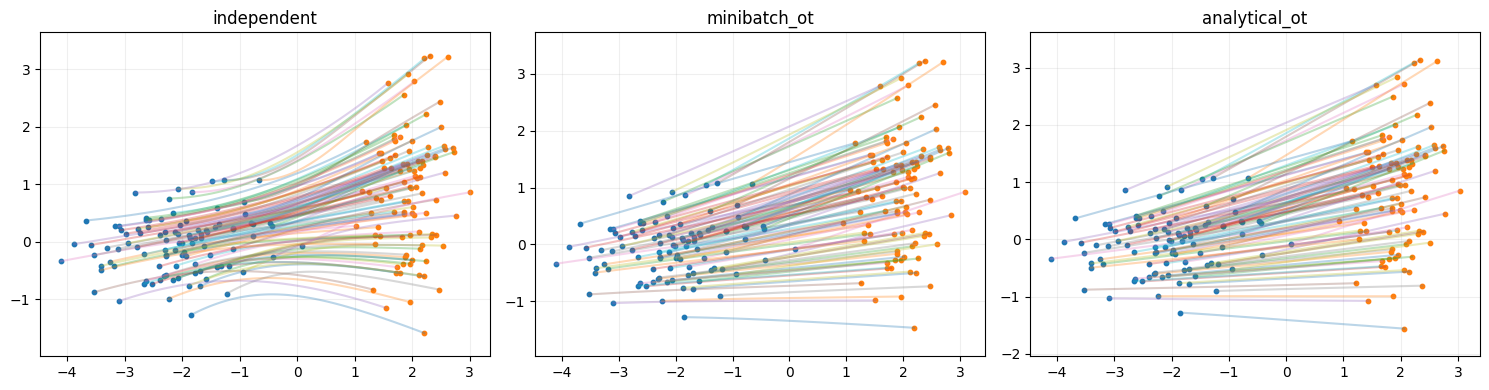

In [16]:
x0_vis = sample_q0(100)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (method, model) in zip(axes, models.items()):
    _, _, path = ode_sample(
        model,
        x0_vis,
        steps=100,
        solver="rk4",
        return_path=True
    )

    path = path.cpu().numpy()

    for i in range(path.shape[1]):
        ax.plot(
            path[:, i, 0],
            path[:, i, 1],
            alpha=0.3
        )

    ax.scatter(
        path[0, :, 0],
        path[0, :, 1],
        s=10,
        label="Source"
    )

    ax.scatter(
        path[-1, :, 0],
        path[-1, :, 1],
        s=10,
        label="Generated"
    )

    ax.set_title(method)
    ax.axis("equal")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 预期结论

Analytical OT-CFM 应当最接近理论 Dynamic OT。

Minibatch OT-CFM 通常次之。

I-CFM 可能具有更高的 Path Energy。

但要注意：

**只有当生成终点分布也足够接近目标分布时，NPE 才能用于判断动态运输的最优性。**

---

# 七、实验 5：验证 OT-CFM 降低监督目标条件方差

## 7.1 验证目标

对于：

$$
U=X_1-X_0
$$

CFM 实际学习的是：

$$
v^*(t,x)=\mathbb E[U\mid X_t=x]
$$

因此监督目标中的不可约误差为：

$$
\boxed{
\mathbb E\left[
\|U-\mathbb E[U\mid t,X_t]\|^2
\right]
}
\tag{15}
$$

我们希望比较不同 Coupling 下的这个条件方差。

这里有一个更好的实验方法：

**由于本实验使用高斯分布，我们可以直接推导条件方差，而不需要用网格近似。**

## 7.2 Independent Coupling 的解析条件方差

设：

$$
X_0\sim\mathcal N(\mu_0,\Sigma_0)
$$

$$
X_1\sim\mathcal N(\mu_1,\Sigma_1)
$$

且相互独立。

定义：

$$
U=X_1-X_0
$$

$$
X_t=(1-t)X_0+tX_1+\sigma Z
$$

则：

$$
\operatorname{Cov}(U)
=
\Sigma_0+\Sigma_1
$$

$$
\operatorname{Cov}(X_t)
=
(1-t)^2\Sigma_0+t^2\Sigma_1+\sigma^2I
$$

$$
\operatorname{Cov}(U,X_t)
=
-(1-t)\Sigma_0+t\Sigma_1
$$

由于它们联合高斯，条件协方差为：

$$
\boxed{
\begin{aligned}
\Sigma_{U\mid X_t}
={}&
\Sigma_U\\
&-
\Sigma_{UX}
\Sigma_X^{-1}
\Sigma_{XU}
\end{aligned}
}
\tag{16}
$$

因此条件速度的均方方差为：

$$
\boxed{
V(t)=\operatorname{Tr}(\Sigma_{U\mid X_t})
}
\tag{17}
$$

对于 Analytical OT Coupling：

$$
X_1=T(X_0)
$$

可以类似推导。

由于所有变量仍然是联合高斯，条件方差也具有解析解。

## 7.3 统一解析计算



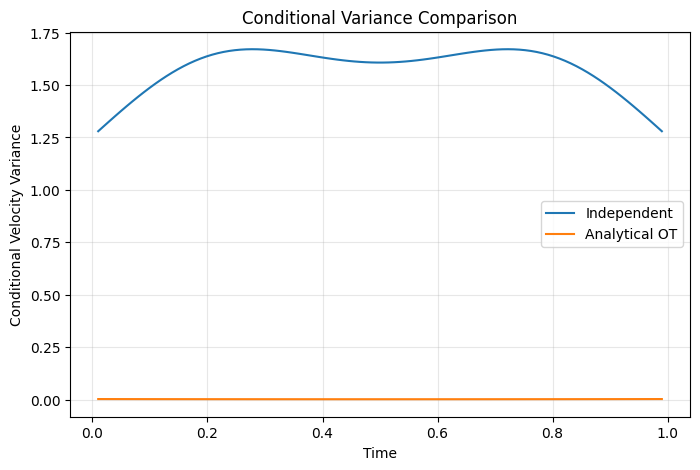

Mean variance Independent: 1.5788112926483153
Mean variance OT: 0.002479320764541626


In [17]:
@torch.no_grad()
def conditional_velocity_variance(method, t, sigma=0.05):
    I = torch.eye(2, device=device)

    if method == "independent":
        # Cov(X0, X1) = 0
        C01 = torch.zeros(2, 2, device=device)

    elif method == "analytical_ot":
        # X1 = mu1 + A(X0-mu0)
        C01 = Sigma0 @ A.T

    else:
        raise ValueError(method)

    # U = X1-X0
    Sigma_U = Sigma0 + Sigma1 - C01 - C01.T

    # Xt = (1-t)X0+tX1+sigma*Z
    Sigma_X = (
        (1-t)**2 * Sigma0
        + t**2 * Sigma1
        + t*(1-t)*(C01 + C01.T)
        + sigma**2 * I
    )

    # Cov(U, Xt)
    Sigma_UX = (
        -(1-t)*Sigma0
        + t*Sigma1
        + (1-t)*C01.T
        - t*C01
    )

    Sigma_cond = (
        Sigma_U
        - Sigma_UX
        @ torch.linalg.solve(Sigma_X, Sigma_UX.T)
    )

    return torch.trace(Sigma_cond).item()

ts_var = np.linspace(0.01, 0.99, 100)

var_ind = [
    conditional_velocity_variance("independent", t)
    for t in ts_var
]

var_ot = [
    conditional_velocity_variance("analytical_ot", t)
    for t in ts_var
]

plt.figure(figsize=(8, 5))
plt.plot(ts_var, var_ind, label="Independent")
plt.plot(ts_var, var_ot, label="Analytical OT")
plt.xlabel("Time")
plt.ylabel("Conditional Velocity Variance")
plt.title("Conditional Variance Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Mean variance Independent:", np.mean(var_ind))
print("Mean variance OT:", np.mean(var_ot))


### 预期结果

Analytical OT Coupling 的条件方差应该显著低于 Independent Coupling。

特别是：

$$
\sigma\rightarrow0
$$

时，在这个高斯 Monge Map 设置下：

$$
\boxed{
\operatorname{Var}(U\mid X_t)\rightarrow0
}
$$

因为中间状态可以唯一确定起点，从而唯一确定速度。

而 Independent Coupling 即使：

$$
\sigma=0
$$

通常仍然具有非零条件方差。

这就验证了论文中关于 OT-CFM 降低监督不确定性的理论解释。

---

# 八、实验 6：验证 ODE 采样效率

## 8.1 验证目标

比较：

$$
N\in\{2,4,8,16,32,64\}
$$

个积分步数下的生成质量。

分别使用：

- Euler
- Heun

注意：

$$
\mathrm{NFE}_{\mathrm{Euler}}=N
$$

$$
\mathrm{NFE}_{\mathrm{Heun}}=2N
$$

我们比较两个指标。

**指标一：生成分布误差**

$$
W_2(\widehat p_1,q_1)
$$

**指标二：数值积分误差**

与高精度 RK4 结果比较：

$$
\boxed{
E_{\mathrm{ODE}}
=
\mathbb E\|X_1^{(N)}-X_1^{\mathrm{RK4}}\|^2
}
\tag{18}
$$

## 8.2 实验代码



In [18]:
x0_eval = sample_q0(2048)

steps_list = [2, 4, 8, 16, 32, 64]

sampling_results = []

for method, model in models.items():
    model.eval()

    # 高精度参考解
    x_ref, _ = ode_sample(
        model,
        x0_eval,
        steps=400,
        solver="rk4"
    )

    for solver in ["euler", "heun"]:
        for steps in steps_list:
            x_pred, _ = ode_sample(
                model,
                x0_eval,
                steps=steps,
                solver=solver
            )

            nfe = steps if solver == "euler" else 2 * steps

            ode_error = (
                (x_pred - x_ref).square().sum(-1).mean().item()
            )

            gen_error = empirical_gaussian_w2(
                x_pred, mu1, Sigma1
            )

            sampling_results.append({
                "Method": method,
                "Solver": solver,
                "Steps": steps,
                "NFE": nfe,
                "ODE Error": ode_error,
                "Generation Error": gen_error
            })

df_sampling = pd.DataFrame(sampling_results)
print(df_sampling.head())


        Method Solver  Steps  NFE  ODE Error  Generation Error
0  independent  euler      2    2   0.521935          0.684896
1  independent  euler      4    4   0.146976          0.348567
2  independent  euler      8    8   0.040906          0.171329
3  independent  euler     16   16   0.010919          0.082499
4  independent  euler     32   32   0.002829          0.051197


### 绘制采样效率曲线


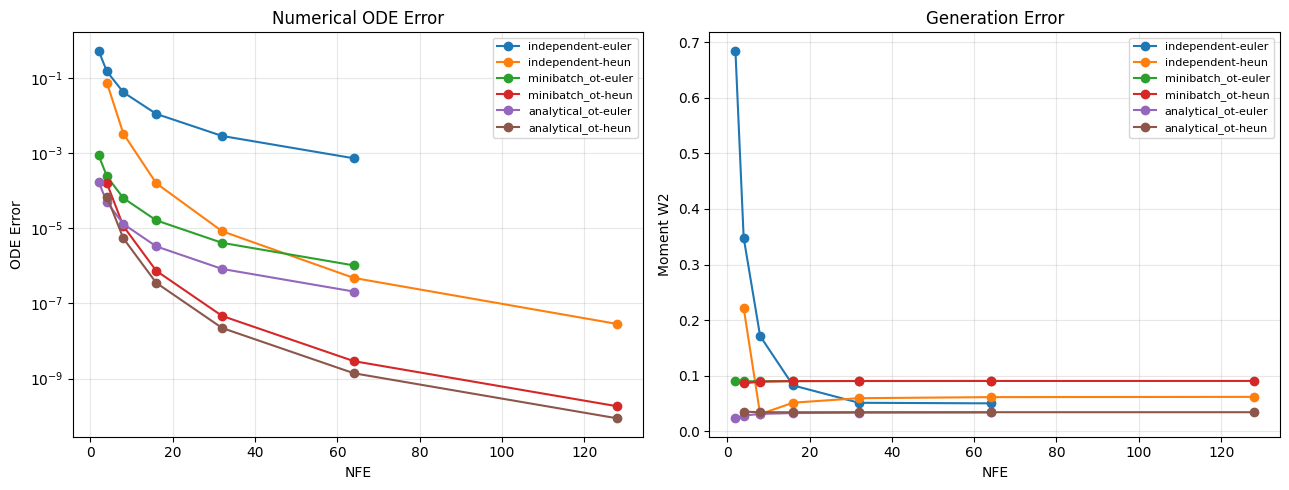

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for method in models.keys():
    for solver in ["euler", "heun"]:
        sub = df_sampling[
            (df_sampling["Method"] == method)
            & (df_sampling["Solver"] == solver)
        ].sort_values("NFE")

        label = f"{method}-{solver}"

        axes[0].plot(
            sub["NFE"],
            sub["ODE Error"],
            marker="o",
            label=label
        )

        axes[1].plot(
            sub["NFE"],
            sub["Generation Error"],
            marker="o",
            label=label
        )

axes[0].set_title("Numerical ODE Error")
axes[0].set_xlabel("NFE")
axes[0].set_ylabel("ODE Error")
axes[0].set_yscale("log")

axes[1].set_title("Generation Error")
axes[1].set_xlabel("NFE")
axes[1].set_ylabel("Moment W2")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


### 如何分析？

如果 OT-CFM 学到的速度场更加接近线性位移插值，那么通常可以用更少的积分步数获得较低误差。

不过这个结论不是必然成立。

因为数值积分误差还受到：

$$
\frac{\partial v_\theta}{\partial t}
$$

以及：

$$
\frac{\partial v_\theta}{\partial x}
$$

等因素影响。

所以实验需要分别观察：

- 动态运输是否更优。
- ODE 是否更容易积分。

不能将这两个结论直接等同。

---

# 九、实验 7：验证 SB-CFM 恢复 Schrödinger Bridge

这一部分使用一维高斯，方便获得解析 Ground Truth。

## 9.1 数据分布

选择：

$$
q_0=\mathcal N(-2,1)
$$

$$
q_1=\mathcal N(2,1)
$$

参考布朗运动：

$$
dX_t=\sigma\,dW_t
$$

取：

$$
\sigma=0.5
$$

因此：

$$
\varepsilon=2\sigma^2=0.5
$$

## 9.2 解析 Entropic OT Coupling

两个一维高斯之间的最优熵正则化 Coupling 是联合高斯：

$$
\begin{bmatrix}
X_0\\X_1
\end{bmatrix}
\sim
\mathcal N
\left(
\begin{bmatrix}
-2\\2
\end{bmatrix},
\begin{bmatrix}
1&c\\
c&1
\end{bmatrix}
\right)
$$

其中：

$$
\boxed{
c=
\frac{\sqrt{\varepsilon^2+16}-\varepsilon}{4}
}
\tag{19}
$$

给定：

$$
\varepsilon=0.5
$$

得到：

$$
c\approx0.8828
$$

## 9.3 Brownian Bridge 条件路径

$$
\boxed{
X_t=(1-t)X_0+tX_1
+\sigma\sqrt{t(1-t)}Z
}
\tag{20}
$$

其中：

$$
Z\sim\mathcal N(0,1)
$$

目标速度：

$$
\boxed{
U_t=
X_1-X_0+
\frac{\sigma(1-2t)}
{2\sqrt{t(1-t)}}Z
}
\tag{21}
$$

解析边缘分布为：

$$
\boxed{
p_t=\mathcal N(m_t,s_t^2)
}
\tag{22}
$$

其中：

$$
\boxed{
m_t=-2+4t
}
\tag{23}
$$

$$
\boxed{
s_t^2=
(1-t)^2+t^2
+2t(1-t)c
+\sigma^2t(1-t)
}
\tag{24}
$$

这就是我们需要验证的 Ground Truth。

## 9.4 实验代码

### 构造解析 SB


In [20]:
sigma_sb = 0.5
epsilon = 2 * sigma_sb**2

c = (np.sqrt(epsilon**2 + 16) - epsilon) / 4

print("Optimal covariance:", c)

def sample_sb_endpoints(n):
    z0 = torch.randn(n, 1, device=device)
    z1 = torch.randn(n, 1, device=device)

    x0 = -2 + z0
    x1 = 2 + c * z0 + np.sqrt(1 - c**2) * z1

    return x0, x1

def sb_analytical_marginal(t):
    mean = -2 + 4*t

    var = (
        (1-t)**2
        + t**2
        + 2*t*(1-t)*c
        + sigma_sb**2*t*(1-t)
    )

    return mean, var


Optimal covariance: 0.8827822185373186


### 训练 SB-CFM


In [21]:
def train_sb_cfm(steps=5000, batch_size=512):
    model = VelocityMLP(dim=1, hidden=128).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    losses = []

    for step in range(steps):
        x0, x1 = sample_sb_endpoints(batch_size)

        # 避免 t=0 和 t=1
        t = 0.001 + 0.998 * torch.rand(
            batch_size, 1, device=device
        )

        z = torch.randn_like(x0)

        # Brownian Bridge
        xt = (
            (1-t)*x0
            + t*x1
            + sigma_sb*torch.sqrt(t*(1-t))*z
        )

        # Probability Flow ODE 的条件速度
        target = (
            x1 - x0
            + sigma_sb*(1-2*t)
            / (2*torch.sqrt(t*(1-t))) * z
        )

        pred = model(xt, t)

        loss = F.mse_loss(pred, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        losses.append(loss.item())

        if (step + 1) % 1000 == 0:
            print(
                f"SB-CFM step={step+1}, "
                f"loss={loss.item():.6f}"
            )

    return model, losses

sb_model, sb_losses = train_sb_cfm(steps=SB_TRAIN_STEPS)


SB-CFM step=1000, loss=0.567224


SB-CFM step=2000, loss=0.628094


SB-CFM step=3000, loss=1.057960


SB-CFM step=4000, loss=0.584751


SB-CFM step=5000, loss=0.668940


### 验证边缘概率分布


In [22]:
@torch.no_grad()
def sb_rollout(model, n=10000, steps=200):
    x = -2 + torch.randn(n, 1, device=device)

    dt = 1.0 / steps

    means = [x.mean().item()]
    variances = [x.var(unbiased=False).item()]

    for k in range(steps):
        t = k * dt

        # Heun
        k1 = model(x, t)
        x_pred = x + dt*k1
        k2 = model(x_pred, t + dt)

        x = x + 0.5*dt*(k1+k2)

        means.append(x.mean().item())
        variances.append(x.var(unbiased=False).item())

    return np.array(means), np.array(variances)

sb_means, sb_vars = sb_rollout(sb_model)

ts_sb = np.linspace(0, 1, len(sb_means))

true_means = []
true_vars = []

for t in ts_sb:
    m, v = sb_analytical_marginal(t)
    true_means.append(m)
    true_vars.append(v)

true_means = np.array(true_means)
true_vars = np.array(true_vars)


### 可视化


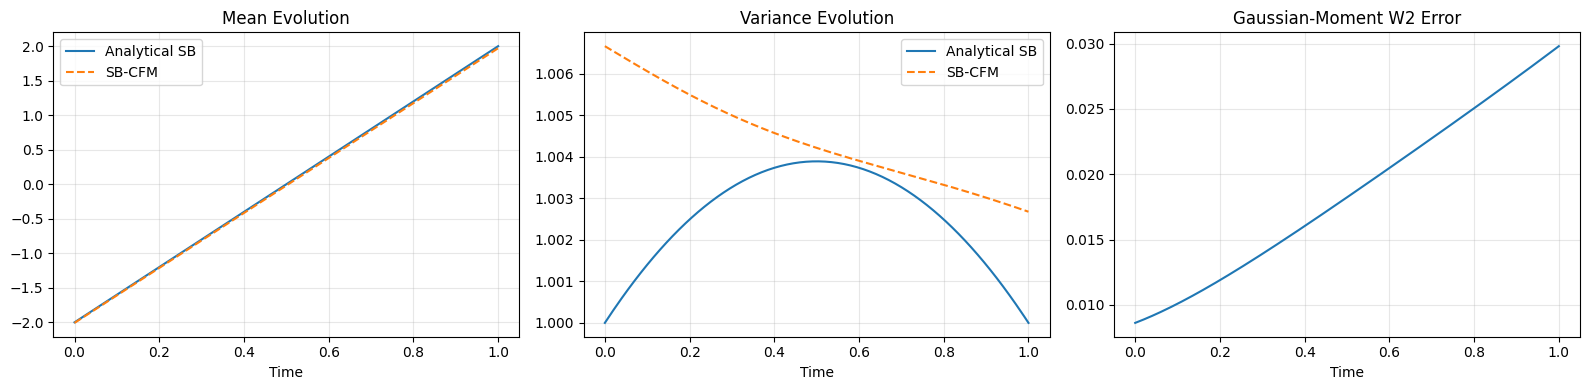

Mean Error: 0.01842446750567405
Variance Error: 0.0018058966392157077
Mean Moment W2: 0.018497512306626558


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(
    ts_sb, true_means,
    label="Analytical SB"
)
axes[0].plot(
    ts_sb, sb_means,
    "--", label="SB-CFM"
)
axes[0].set_title("Mean Evolution")
axes[0].legend()

axes[1].plot(
    ts_sb, true_vars,
    label="Analytical SB"
)
axes[1].plot(
    ts_sb, sb_vars,
    "--", label="SB-CFM"
)
axes[1].set_title("Variance Evolution")
axes[1].legend()

# 一维高斯 W2^2 = (m1-m2)^2 + (s1-s2)^2
w2_errors = np.sqrt(
    (sb_means - true_means)**2
    + (np.sqrt(sb_vars) - np.sqrt(true_vars))**2
)

axes[2].plot(ts_sb, w2_errors)
axes[2].set_title("Gaussian-Moment W2 Error")

for ax in axes:
    ax.set_xlabel("Time")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Mean Error:", np.mean(np.abs(sb_means - true_means)))
print("Variance Error:", np.mean(np.abs(sb_vars - true_vars)))
print("Mean Moment W2:", np.mean(w2_errors))


### 预期结果

SB-CFM 生成的均值演化应该接近：

$$
m_t=-2+4t
$$

方差演化应该接近：

$$
s_t^2=
(1-t)^2+t^2
+2t(1-t)c
+\sigma^2t(1-t)
$$

尤其需要观察中间时刻：

$$
t=0.5
$$

因为这时 Brownian Bridge 的条件噪声方差最大。

如果模型训练充分，预测曲线应当接近解析曲线。

这验证了：

$$
\boxed{
p_t^{\mathrm{SB-CFM}}
\approx
p_t^{\mathrm{Schrödinger\ Bridge}}
}
$$

需要注意，这里的实验比较的是**边缘概率分布**，并不是随机路径本身。

---

# 十、最终实验结果应该如何整理？

建议最后在 Notebook 中整理出以下结果。

| 验证内容 | 理论预期 | 实验指标 |
|---|---|---|
| Static OT 最优性 | OT 成本不高于独立耦合 | Coupling Cost |
| Static OT → Dynamic OT | Path Energy = $W_2^2$ | Energy Error |
| OT-CFM 逼近 Dynamic OT | OT-CFM 的 NPE 较低 | NPE + 终点误差 |
| OT-CFM 降低监督方差 | OT Coupling 的条件方差更低 | Conditional Variance |
| OT-CFM 采样效率 | 相同 NFE 下误差可能更低 | NFE vs W2 |
| SB-CFM 边缘一致性 | ODE 边缘接近解析 SB | Mean、Variance、W2 |

## 十一、这套实验能够得出什么结论？

这套实验实际上把论文的结论分成了两个层次。

### 第一层：验证数学理论

不依赖神经网络，可以直接验证：

$$
\boxed{
\text{Static OT}
+
\text{Linear Interpolation}
=
\text{Dynamic OT}
}
$$

以及：

$$
\boxed{
\text{Analytical OT Coupling}
\Longrightarrow
\text{较低的条件速度监督方差}
}
$$

这两个实验有解析 Ground Truth，因此结论最明确。

### 第二层：验证神经网络是否能够学习这些理论性质

通过 I-CFM、Minibatch OT-CFM 和 Analytical OT-CFM 的训练，观察：

$$
\boxed{
\text{更好的 Coupling}
\Longrightarrow
\text{更接近最优的生成概率流？}
}
$$

以及：

$$
\boxed{
\text{更接近 OT 的概率流}
\Longrightarrow
\text{更高的 ODE 采样效率？}
}
$$

最后使用一维高斯 SB-CFM 验证：

$$
\boxed{
\text{Entropic OT}
+
\text{Brownian Bridge}
\Longrightarrow
\text{Schrödinger Bridge 的边缘概率流}
}
$$

**这套 Notebook 的重点是：每个核心结论都有对应的解析参考、可计算指标和可视化结果，而不是只观察训练 Loss。**

另外有两个实验边界需要明确：高斯矩匹配 W2 不能完全衡量非高斯生成分布；SB-CFM 的一维高斯实验验证的是解析熵正则化耦合版本，不等于验证 Minibatch Sinkhorn 的近似精度。这两点不会影响主要理论验证，但在解释实验结果时需要区分。
